# Retention and LTV by Acquisition Channel

**Author:** Yelyzaveta Zakharova, Product Analyst
**Data:** fully simulated data of a fictional subscription dating app ("Driftly"). No real company data is used.

**Business question.** Retention has been falling through 2025 and the growth team keeps scaling TikTok because installs there are cheapest.
Is the product getting worse, and which channels actually pay back?

**Data.** 12 monthly install cohorts (Jan–Dec 2025), snapshot on 2026-03-31.
`users.csv.gz` (install date, channel, last active day), `transactions.csv` (every subscription charge, $29.99/month), `marketing_spend.csv` (monthly spend per paid channel).

**Definitions**

- *Rolling retention Dn*: share of installs active on day n or later. Only users at least n days old count.
- *Net revenue*: gross charges minus the 30% app-store fee.
- *LTV12*: net revenue per install within 365 days of install.
- *CAC*: paid spend / paid installs (organic excluded).

In [1]:
import json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

SNAP = pd.Timestamp("2026-03-31"); NET = 0.70; PRICE = 29.99
users = pd.read_csv("data/users.csv.gz", parse_dates=["install_date"])
tx = pd.read_csv("data/transactions.csv", parse_dates=["charge_date"])
spend = pd.read_csv("data/marketing_spend.csv", parse_dates=["month"])
users["cohort"] = users.install_date.dt.to_period("M")
users["age"] = (SNAP - users.install_date).dt.days
tx = tx.merge(users[["user_id", "install_date", "channel", "cohort"]], on="user_id")
tx["day"] = (tx.charge_date - tx.install_date).dt.days
CHANNELS = ["Apple Search Ads", "Meta Ads", "Google App Campaigns", "Influencers", "TikTok Ads", "Organic"]
print(len(users), "installs,", len(tx), "charges")
pd.crosstab(users.cohort, users.channel, normalize="index")[CHANNELS].round(3)

173570 installs, 27551 charges


channel,Apple Search Ads,Meta Ads,Google App Campaigns,Influencers,TikTok Ads,Organic
cohort,,,,,,
2025-01,0.140,0.300,0.160,0.07,0.080,0.250
2025-02,0.136,0.293,0.156,0.07,0.105,0.239
2025-03,0.133,0.285,0.153,0.07,0.131,0.228
2025-04,0.129,0.278,0.149,0.07,0.156,0.217
2025-05,0.125,0.271,0.145,0.07,0.182,0.206
2025-06,0.122,0.264,0.142,0.07,0.207,0.195
2025-07,0.118,0.256,0.138,0.07,0.233,0.185
2025-08,0.115,0.249,0.135,0.07,0.258,0.174
2025-09,0.111,0.242,0.131,0.07,0.284,0.163


## 1. Is retention really falling?
Aggregate D30 retention by cohort, next to the same metric with the **January channel mix held constant**.
If the two lines diverge, the decline comes from the traffic mix, not from the product.

In [2]:
def rolling_ret(df, n):
    e = df[df.age >= n]
    return (e.last_active_day >= n).mean() if len(e) else np.nan

N = 30
cc = (users.groupby(["cohort", "channel"]).apply(lambda d: pd.Series({"n": len(d), "ret": rolling_ret(d, N)}))
      .reset_index())
cc["share"] = cc.n / cc.groupby("cohort").n.transform("sum")
agg = cc.groupby("cohort").apply(lambda d: (d.share * d.ret).sum())
jan_mix = cc[cc.cohort == cc.cohort.min()].set_index("channel").share
fixed = cc.groupby("cohort").apply(lambda d: (d.set_index("channel").ret * jan_mix).sum())
d30 = pd.DataFrame({"actual": agg, "jan_mix_held": fixed})
display(d30.round(4))

first, last = d30.index.min(), d30.index.max()
total = d30.actual[last] - d30.actual[first]
within = d30.jan_mix_held[last] - d30.jan_mix_held[first]
print(f"D30 change Jan->Dec: {total*100:+.1f} pp; within-channel: {within*100:+.1f} pp; "
      f"mix: {(total-within)*100:+.1f} pp ({(total-within)/total:.0%} of the decline)")

,actual,jan_mix_held
cohort,,
2025-01,0.3833,0.3833
2025-02,0.3850,0.3884
2025-03,0.3784,0.3866
2025-04,0.3801,0.3906
2025-05,0.3729,0.3872
2025-06,0.3708,0.3895
2025-07,0.3694,0.3932
2025-08,0.3631,0.3852
2025-09,0.3478,0.3769


D30 change Jan->Dec: -3.4 pp; within-channel: +0.6 pp; mix: -4.0 pp (117% of the decline)


## 2. Channel retention curves: early metrics mislead

In [3]:
days = [1, 3, 7, 14, 30, 60, 90, 120, 180]
curves = pd.DataFrame({ch: [rolling_ret(users[users.channel == ch], n) for n in days] for ch in CHANNELS}, index=days)
display(curves.round(3))
print("Rank by D1:", list(curves.loc[1].sort_values(ascending=False).index))
print("Rank by D90:", list(curves.loc[90].sort_values(ascending=False).index))

,Apple Search Ads,Meta Ads,Google App Campaigns,Influencers,TikTok Ads,Organic
1,0.480,0.522,0.499,0.586,0.615,0.545
3,0.474,0.510,0.486,0.566,0.582,0.539
7,0.461,0.490,0.463,0.526,0.521,0.526
14,0.441,0.456,0.425,0.460,0.428,0.504
30,0.396,0.382,0.348,0.343,0.272,0.460
60,0.322,0.275,0.238,0.197,0.116,0.382
90,0.263,0.199,0.164,0.116,0.050,0.317
120,0.215,0.144,0.112,0.068,0.022,0.263
180,0.145,0.076,0.051,0.021,0.004,0.181


Rank by D1: ['TikTok Ads', 'Influencers', 'Organic', 'Meta Ads', 'Google App Campaigns', 'Apple Search Ads']
Rank by D90: ['Organic', 'Apple Search Ads', 'Meta Ads', 'Google App Campaigns', 'Influencers', 'TikTok Ads']


TikTok has the **best D1** and the **worst D90**. A channel dashboard that judges traffic by D1 or D7 rewards exactly the traffic that leaves fastest.

## 3. Monetization by channel
Three drivers of LTV: payer conversion within 30 days, first-renewal rate, and later renewal rate.
Renewals only count where the next billing date is before the snapshot (right-censoring).

In [4]:
def mon_params(u, t, snap):
    """payer conversion and renewal rates as of a snapshot date (censoring-aware)."""
    u = u[(snap - u.install_date).dt.days >= 30]
    t = t[t.charge_date <= snap]
    payers30 = t[(t.renewal_number == 0) & (t.day < 30)].user_id.unique()
    conv = (u.user_id.isin(payers30)).sum(), len(u)
    t = t.sort_values(["user_id", "renewal_number"])
    t["renewed"] = t.groupby("user_id").renewal_number.shift(-1).notna()
    elig = t[t.charge_date + pd.Timedelta(days=30) <= snap]
    f = elig[elig.renewal_number == 0]; l = elig[elig.renewal_number > 0]
    return dict(conv_k=conv[0], conv_n=conv[1], s1_k=f.renewed.sum(), s1_n=len(f), s_k=l.renewed.sum(), s_n=len(l))

def expected_charges(s1, s, k_max=11):
    """expected charges within 12 months: first charge + up to 11 renewals."""
    return 1 + s1 * (1 - s ** k_max) / (1 - s)

par = {}
for ch in CHANNELS:
    p = mon_params(users[users.channel == ch], tx[tx.channel == ch], SNAP)
    p.update(conv=p["conv_k"] / p["conv_n"], s1=p["s1_k"] / p["s1_n"], s=p["s_k"] / p["s_n"])
    par[ch] = p
mon = pd.DataFrame(par).T[["conv", "s1", "s", "conv_n", "s1_n", "s_n"]].astype(float)
mon["charges_12m"] = expected_charges(mon.s1, mon.s)
mon.round(3)

,conv,s1,s,conv_n,s1_n,s_n,charges_12m
Apple Search Ads,0.076,0.706,0.832,20485.0,1559.0,4446.0,4.651
Meta Ads,0.050,0.620,0.740,44449.0,2235.0,4318.0,3.300
Google App Campaigns,0.048,0.603,0.738,23958.0,1152.0,2145.0,3.221
Influencers,0.032,0.542,0.641,12148.0,391.0,521.0,2.499
TikTok Ads,0.019,0.411,0.599,40573.0,778.0,690.0,2.021
Organic,0.065,0.708,0.826,31957.0,2074.0,5996.0,4.574


## 4. LTV forecast and backtest
Most cohorts are younger than 12 months, so LTV12 has to be forecast:

**LTV12 = 30-day payer conversion × net price × expected charges in 12 months**, with expected charges = 1 + s₁(1 − s¹¹)/(1 − s).

Before trusting it, I **backtest**: estimate the parameters using only data available on 2025-09-30, forecast LTV12 for the Jan–Mar 2025 cohorts, and compare with their actual 12-month revenue, which is fully observed today.

In [5]:
def ltv12_hat(p):
    return p["conv"] * PRICE * NET * expected_charges(p["s1"], p["s"])

BT_SNAP = pd.Timestamp("2025-09-30")
bt = []
for ch in CHANNELS:
    u, t = users[users.channel == ch], tx[tx.channel == ch]
    p = mon_params(u, t, BT_SNAP)
    p.update(conv=p["conv_k"] / p["conv_n"], s1=p["s1_k"] / p["s1_n"], s=p["s_k"] / p["s_n"])
    for c in pd.period_range("2025-01", "2025-03", freq="M"):
        uc = u[u.cohort == c]; tc = t[(t.cohort == c) & (t.day < 365)]
        # cohort's own observed conversion as of the backtest date, pooled renewal rates
        q = mon_params(uc, t[t.cohort == c], BT_SNAP)
        pc = dict(conv=q["conv_k"] / q["conv_n"], s1=p["s1"], s=p["s"])
        bt.append(dict(channel=ch, cohort=str(c), predicted=ltv12_hat(pc),
                       actual=tc.gross_amount_usd.sum() * NET / len(uc)))
bt = pd.DataFrame(bt)
bt["ape"] = (bt.predicted / bt.actual - 1).abs()
btc = bt.groupby("channel")[["predicted", "actual"]].mean().loc[CHANNELS]
btc["error"] = btc.predicted / btc.actual - 1
display(btc.round(3))
print(f"Backtest MAPE across 18 cohort-channel cells: {bt.ape.mean():.1%}; channel-level: {btc.error.abs().mean():.1%}")

,predicted,actual,error
channel,,,
Apple Search Ads,6.547,6.859,-0.045
Meta Ads,3.602,3.602,0.000
Google App Campaigns,3.360,3.365,-0.001
Influencers,1.705,1.623,0.050
TikTok Ads,0.688,0.607,0.134
Organic,5.950,6.087,-0.022


Backtest MAPE across 18 cohort-channel cells: 8.6%; channel-level: 4.2%


## 5. Unit economics: LTV12 / CAC and payback

In [6]:
cac = spend.groupby("channel").agg(spend=("spend_usd", "sum"), installs=("installs", "sum"))
cac["cac"] = cac.spend / cac.installs
rng = np.random.default_rng(1)
rows = []
for ch in CHANNELS:
    p = par[ch]
    draws = []
    for _ in range(4000):   # Bayesian bootstrap of the three drivers (Beta posteriors)
        cv = rng.beta(p["conv_k"] + 1, p["conv_n"] - p["conv_k"] + 1)
        s1 = rng.beta(p["s1_k"] + 1, p["s1_n"] - p["s1_k"] + 1)
        s = rng.beta(p["s_k"] + 1, p["s_n"] - p["s_k"] + 1)
        draws.append(cv * PRICE * NET * expected_charges(s1, s))
    draws = np.array(draws)
    ltv = ltv12_hat(p)
    r = dict(channel=ch, ltv12=ltv, ltv_lo=np.percentile(draws, 2.5), ltv_hi=np.percentile(draws, 97.5))
    if ch in cac.index:
        c = cac.loc[ch, "cac"]
        # payback month: cumulative expected net revenue per install >= CAC
        cum, pay = 0, None
        for m in range(1, 25):
            k = m - 1
            cum = p["conv"] * PRICE * NET * (1 + (p["s1"] * (1 - p["s"] ** k) / (1 - p["s"]) if k > 0 else 0))
            if cum >= c and pay is None:
                pay = m
        r.update(cac=c, spend=cac.loc[ch, "spend"], roi=ltv / c, roi_lo=np.percentile(draws, 2.5) / c,
                 roi_hi=np.percentile(draws, 97.5) / c, payback_month=pay)
    rows.append(r)
ue = pd.DataFrame(rows).set_index("channel")
display(ue.round(2))

tt = spend[spend.channel == "TikTok Ads"].set_index("month")
tt_cpi = tt.spend_usd / tt.installs
print(f"TikTok CPI: Jan {tt_cpi.iloc[0]:.2f} -> Dec {tt_cpi.iloc[-1]:.2f} ({tt_cpi.iloc[-1]/tt_cpi.iloc[0]-1:+.0%}) as spend grew "
      f"{tt.spend_usd.iloc[-1]/tt.spend_usd.iloc[0]:.1f}x")

,ltv12,ltv_lo,ltv_hi,cac,spend,roi,roi_lo,roi_hi,payback_month
channel,,,,,,,,,
Apple Search Ads,7.43,6.96,7.91,4.57,93524.27,1.63,1.53,1.73,5.0
Meta Ads,3.48,3.29,3.68,3.26,144902.19,1.07,1.01,1.13,8.0
Google App Campaigns,3.25,3.01,3.50,2.32,55610.72,1.40,1.30,1.51,4.0
Influencers,1.69,1.49,1.92,2.81,34161.96,0.60,0.53,0.68,NaN
TikTok Ads,0.81,0.74,0.89,1.84,74510.64,0.44,0.41,0.49,NaN
Organic,6.23,5.89,6.57,NaN,NaN,NaN,NaN,NaN,NaN


TikTok CPI: Jan 1.54 -> Dec 2.10 (+36%) as spend grew 10.1x


## 6. Budget scenario
Move 60% of the 2025 TikTok budget to the three channels that pay back (Apple Search Ads, Meta, Google), in proportion to their current spend.
Scaling a channel raises its CAC, so the scenario **assumes +25% CAC on the extra spend**. This is an assumption to validate with a gradual budget shift, not a measured fact.

In [7]:
move = 0.60 * ue.loc["TikTok Ads", "spend"]
recv = ["Apple Search Ads", "Meta Ads", "Google App Campaigns"]
w = ue.loc[recv, "spend"] / ue.loc[recv, "spend"].sum()
lost = move / ue.loc["TikTok Ads", "cac"] * ue.loc["TikTok Ads", "ltv12"]
gain = sum(move * w[ch] / (ue.loc[ch, "cac"] * 1.25) * ue.loc[ch, "ltv12"] for ch in recv)
paid = ue.dropna(subset=["cac"])
base_rev = (paid.spend / paid.cac * paid.ltv12).sum()
scen = dict(moved=move, lost=lost, gained=gain, net=gain - lost, base_rev=base_rev, total_spend=paid.spend.sum(),
            base_roi=base_rev / paid.spend.sum(), new_roi=(base_rev - lost + gain) / paid.spend.sum())
print(f"Move ${move:,.0f}: lose ${lost:,.0f}, gain ${gain:,.0f} -> net +${gain-lost:,.0f} 12-month net revenue "
      f"({(gain-lost)/base_rev:+.0%}); paid ROI {scen['base_roi']:.2f} -> {scen['new_roi']:.2f} at the same budget")

Move $44,706: lose $19,804, gain $46,820 -> net +$27,015 12-month net revenue (+6%); paid ROI 1.09 -> 1.16 at the same budget


## 7. Conclusions

1. **Retention is not getting worse within any channel.** Most of the aggregate D30 drop is the shift of installs toward TikTok.
2. **TikTok looks best on D1 and is worst on everything that makes money:** lowest payer conversion, lowest renewals, LTV12 below CAC, and its CAC rose as the budget grew.
3. **Apple Search Ads is the most expensive install and the best investment.** Meta and Google pay back within the year. Influencers do not.
4. **Recommendation:** cut TikTok and Influencers to test-level budgets, shift spend gradually into Apple Search Ads, Meta and Google while watching their marginal CAC, and judge channels on predicted LTV / CAC, not on CPI or D1.

## Charts

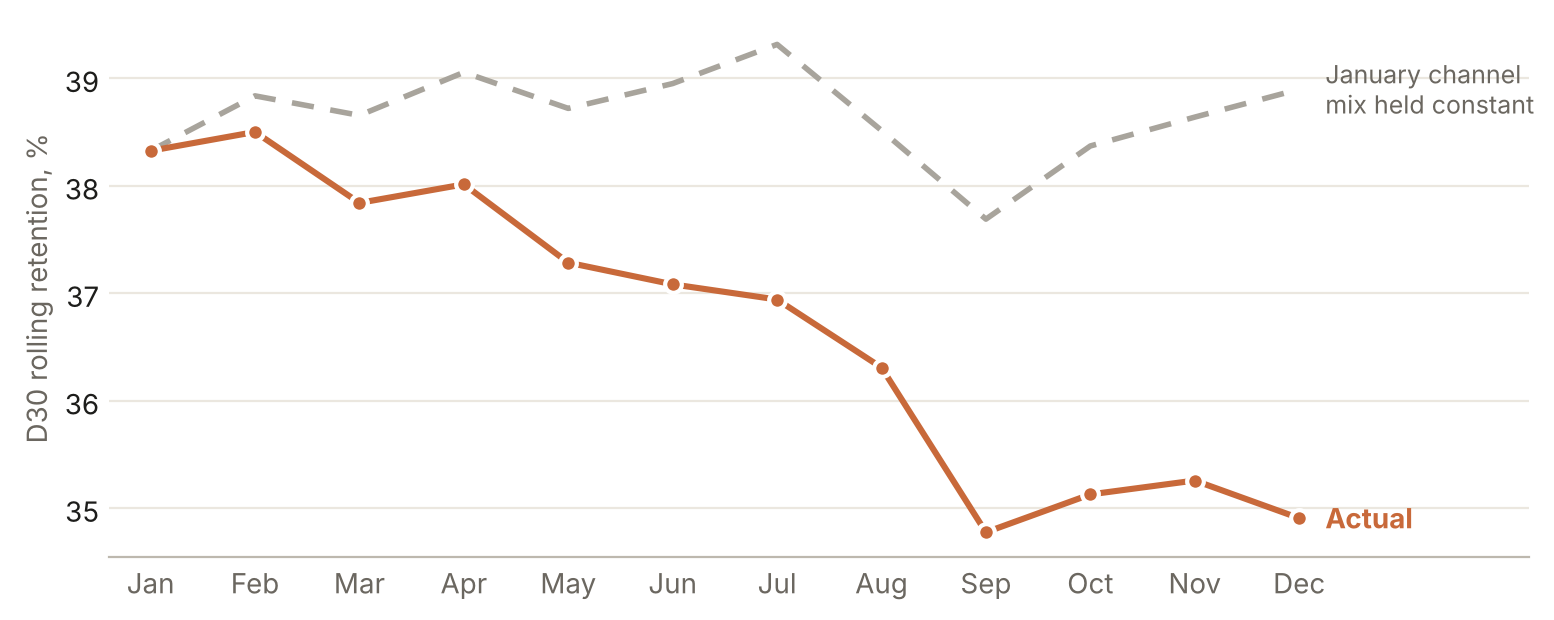

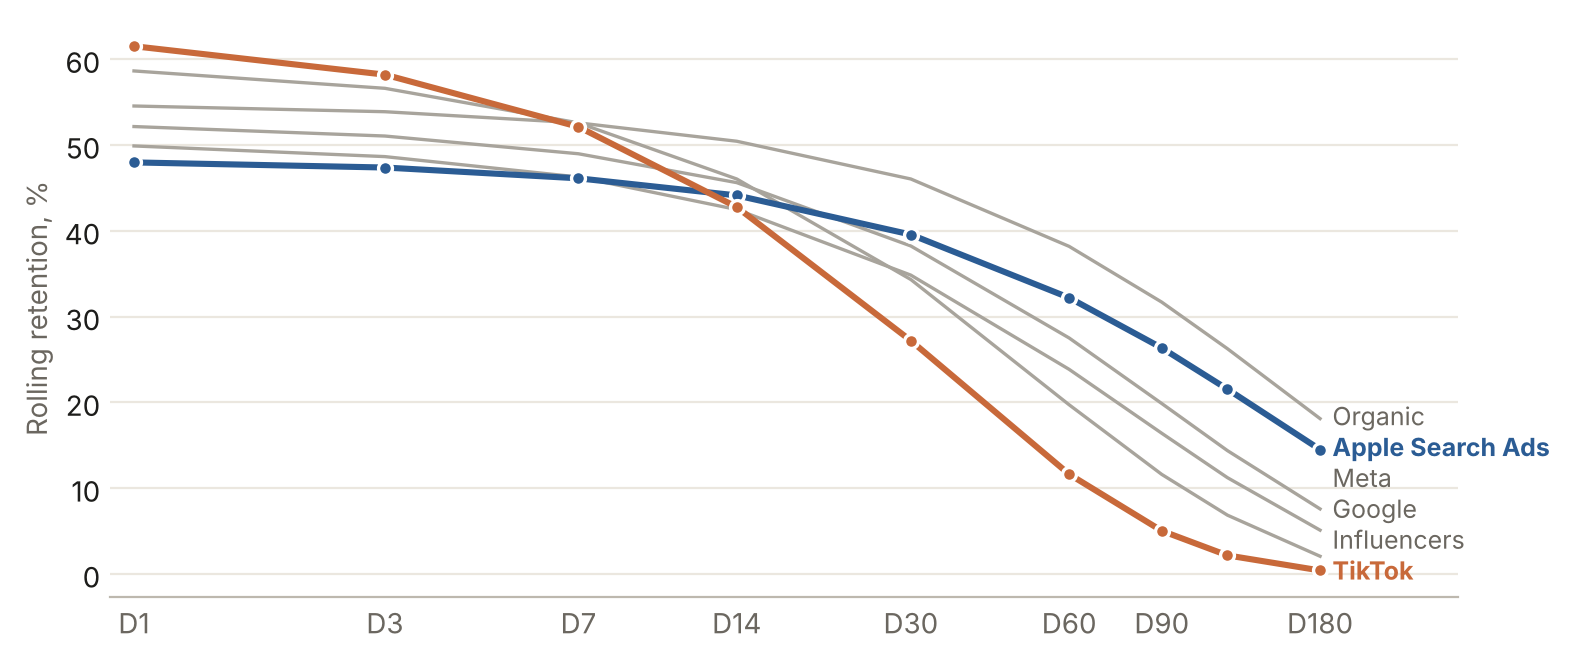

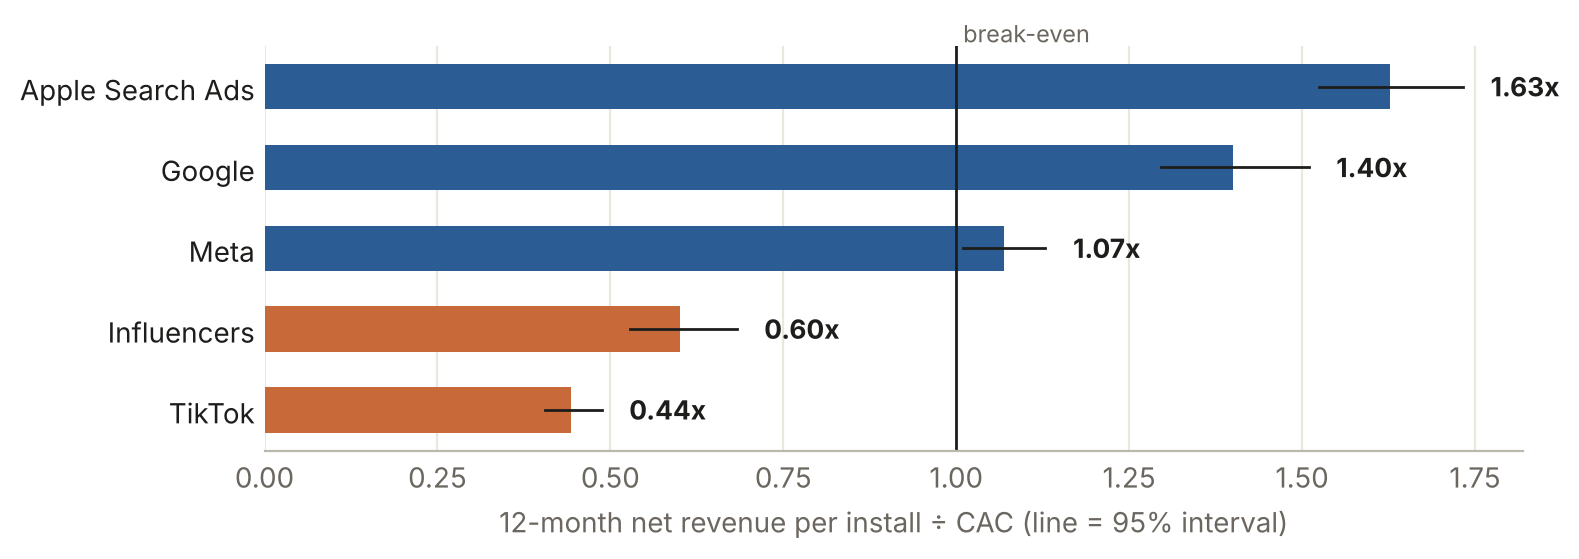

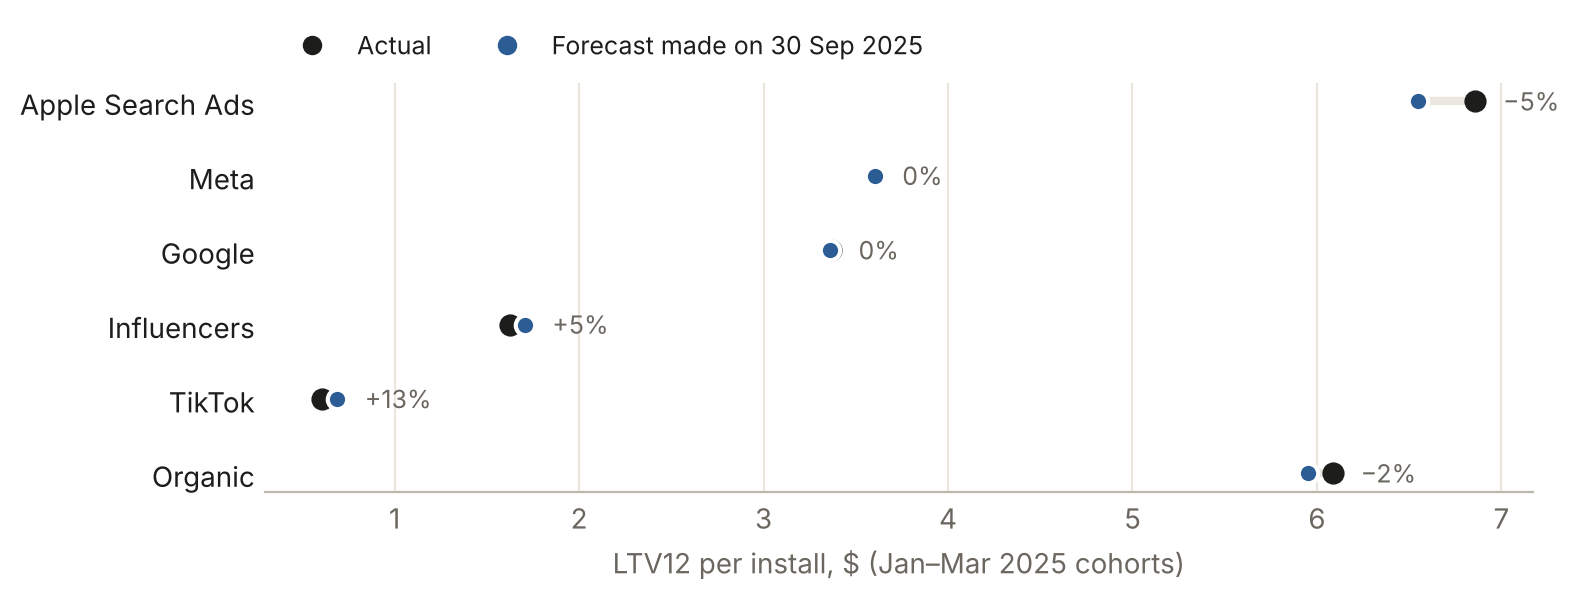

In [8]:
W, M, INK, INK2, RULE, GRID = "#2b5c94", "#c8693a", "#1d1d1b", "#6b6760", "#bdb8ae", "#ebe7df"
OTHER = "#a8a49c"
plt.rcParams.update({"font.family": "Inter", "font.size": 10, "text.color": INK, "axes.spines.top": False,
    "axes.spines.right": False, "axes.spines.left": False, "axes.edgecolor": RULE, "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK, "xtick.major.size": 0, "ytick.major.size": 0, "savefig.transparent": True})
short = {"Apple Search Ads": "Apple Search Ads", "Meta Ads": "Meta", "Google App Campaigns": "Google",
         "Influencers": "Influencers", "TikTok Ads": "TikTok", "Organic": "Organic"}

# E1: D30 actual vs fixed mix
fig, ax = plt.subplots(figsize=(8, 3.2))
x = np.arange(len(d30)); lab = [p.strftime("%b") for p in d30.index]
ax.plot(x, d30.jan_mix_held * 100, color=OTHER, lw=2, ls=(0, (4, 3)))
ax.plot(x, d30.actual * 100, color=M, lw=2.2, marker="o", ms=6, mec="white", mew=1.5)
ax.text(11.25, d30.actual.iloc[-1] * 100, "Actual", color=M, va="center", fontweight="bold")
ax.text(11.25, d30.jan_mix_held.iloc[-1] * 100, "January channel\nmix held constant", color=INK2, va="center", fontsize=9)
ax.set_xticks(x, lab); ax.set_xlim(-0.4, 13.2); ax.set_ylabel("D30 rolling retention, %")
ax.grid(axis="y", color=GRID, lw=.8); ax.set_axisbelow(True)
fig.tight_layout(); fig.savefig("charts/e1_mix.png", dpi=240)

# E2: retention curves, highlight TikTok and ASA
fig, ax = plt.subplots(figsize=(8, 3.4))
for ch in CHANNELS:
    c = {"TikTok Ads": M, "Apple Search Ads": W}.get(ch, OTHER); hl = c != OTHER
    ax.plot(days, curves[ch] * 100, color=c, lw=2.2 if hl else 1.2, marker="o" if hl else None, ms=5,
            mec="white", mew=1.2, zorder=3 if hl else 2)
# direct labels at the right end, spread so they never overlap
ends = sorted([(curves.loc[180, ch] * 100, ch) for ch in CHANNELS])
pos, gap = [], 3.6
for v, ch in ends:
    pos.append(max(v, pos[-1] + gap) if pos else v)
for (v, ch), yv in zip(ends, pos):
    c = {"TikTok Ads": M, "Apple Search Ads": W}.get(ch, OTHER); hl = c != OTHER
    ax.text(190, yv, short[ch], color=c if hl else INK2, va="center", fontsize=9, fontweight="bold" if hl else "normal")
ax.set_xscale("log"); ax.set_xticks(days, [f"D{d}" if d != 120 else "" for d in days]); ax.minorticks_off()
ax.set_xlim(0.9, 330); ax.set_ylabel("Rolling retention, %")
ax.grid(axis="y", color=GRID, lw=.8); ax.set_axisbelow(True)
fig.tight_layout(); fig.savefig("charts/e2_curves.png", dpi=240)

# E3: LTV12 / CAC
p3 = ue.dropna(subset=["cac"]).sort_values("roi")
fig, ax = plt.subplots(figsize=(8, 2.9))
y = np.arange(len(p3))
for yi, (ch, r) in zip(y, p3.iterrows()):
    c = W if r.roi >= 1 else M
    ax.barh(yi, r.roi, color=c, height=.56)
    ax.plot([r.roi_lo, r.roi_hi], [yi, yi], color=INK, lw=1)
    ax.text(r.roi_hi + .04, yi, f"{r.roi:.2f}x", va="center", fontsize=9.5, fontweight="bold")
ax.axvline(1, color=INK, lw=1); ax.text(1.01, len(p3) - .45, "break-even", fontsize=8.5, color=INK2)
ax.set_yticks(y, [short[c] for c in p3.index]); ax.set_xlabel("12-month net revenue per install ÷ CAC (line = 95% interval)")
ax.grid(axis="x", color=GRID, lw=.8); ax.set_axisbelow(True)
fig.tight_layout(); fig.savefig("charts/e3_roi.png", dpi=240)

# E4: backtest
fig, ax = plt.subplots(figsize=(8, 3.1))
b = btc.iloc[::-1]; y = np.arange(len(b))
for yi, (ch, r) in zip(y, b.iterrows()):
    ax.plot([r.actual, r.predicted], [yi, yi], color=GRID, lw=3, zorder=1)
    ax.plot(r.actual, yi, "o", color=INK, ms=7, zorder=3)
    ax.plot(r.predicted, yi, "o", color=W, ms=7, mec="white", mew=1.5, zorder=4)
    ax.text(max(r.actual, r.predicted) + .15, yi, ("0%" if abs(r.error) < 0.005 else f"{r.error:+.0%}".replace("-", "−")), va="center", fontsize=9, color=INK2)
ax.set_yticks(y, [short[c] for c in b.index]); ax.set_xlabel("LTV12 per install, $ (Jan–Mar 2025 cohorts)")
ax.plot([], [], "o", color=INK, label="Actual"); ax.plot([], [], "o", color=W, label="Forecast made on 30 Sep 2025")
ax.legend(frameon=False, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, fontsize=9)
ax.grid(axis="x", color=GRID, lw=.8); ax.set_axisbelow(True)
fig.tight_layout(); fig.savefig("charts/e4_backtest.png", dpi=240)
plt.show()

In [9]:
out = dict(n_users=len(users), n_tx=len(tx), d30=d30.reset_index().assign(cohort=lambda d: d.cohort.astype(str)).to_dict("records"),
           d30_total=total, d30_within=within, curves=curves.to_dict(), mon=mon.to_dict("index"),
           ue=ue.reset_index().to_dict("records"), backtest=btc.reset_index().to_dict("records"),
           bt_mape_cells=bt.ape.mean(), bt_mape_channel=btc.error.abs().mean(),
           tiktok_cpi=[tt_cpi.iloc[0], tt_cpi.iloc[-1]], tiktok_spend_x=tt.spend_usd.iloc[-1] / tt.spend_usd.iloc[0],
           scenario=scen, share=pd.crosstab(users.cohort, users.channel, normalize="index").rename(index=str).to_dict("index"))
json.dump(out, open("results.json", "w"), default=float, indent=1)